/tmp/ipython-input-8-113880244.py:17: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start=start_date, end=end_date, interval = '4h')['Close']
[*********************100%***********************]  2 of 2 completed
/tmp/ipython-input-8-113880244.py:51: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if z_score[i] > entry_z:  # Spread is too high, short EURUSD, long GBPUSD
/tmp/ipython-input-8-113880244.py:56: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  elif z_score[i] < -entry_z:  # Spread is too low, long EURUSD, short GBPUSD
/tmp/ipython-input-8-113880244.py


Performance Metrics:
Sharpe Ratio: 1.7034
Total Return: 0.0195
Max Drawdown: 0.0088


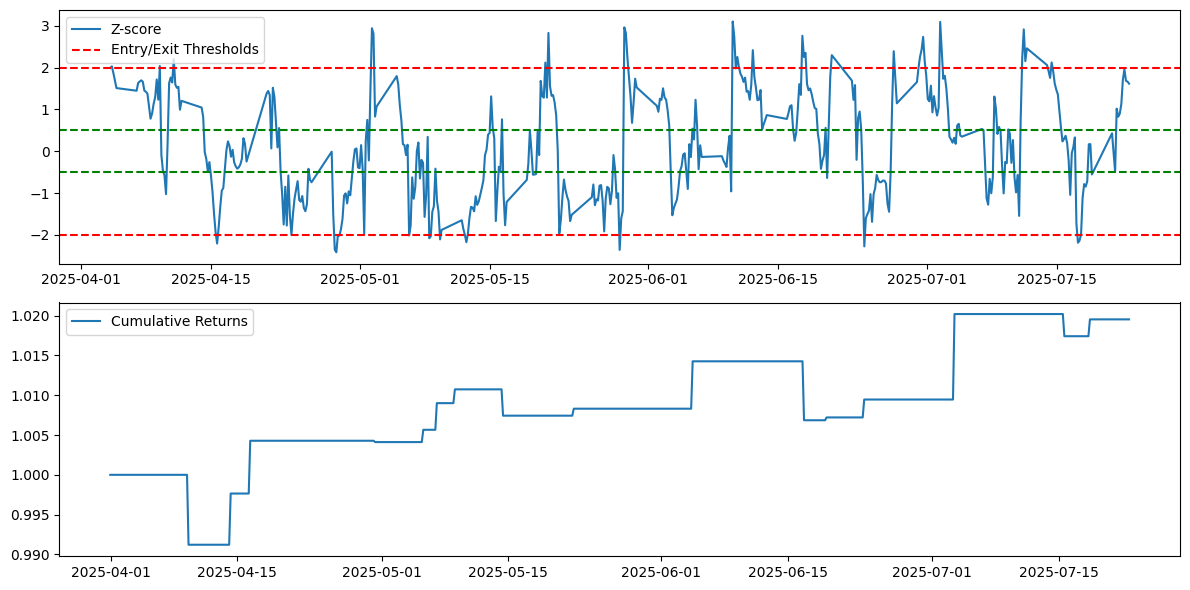

In [8]:
import yfinance as yf
import pandas as pd
import numpy as np
from statsmodels.tsa.stattools import coint
import matplotlib.pyplot as plt

# Parameters
lookback = 20  # Lookback period for calculating spread statistics
entry_z = 2.0  # Entry threshold for z-score
exit_z = 0.5   # Exit threshold for z-score
start_date = "2025-04-01"
end_date = "2025-07-23"

# Fetch historical forex data
def get_forex_data():
    tickers = ['EURUSD=X', 'GBPUSD=X']
    data = yf.download(tickers, start=start_date, end=end_date, interval = '4h')['Close']
    data.columns = ['EURUSD', 'GBPUSD']

    return data

# Calculate spread and z-score
def calculate_spread(data):
    # Test for cointegration
    score, p_value, _ = coint(data['EURUSD'], data['GBPUSD'])
    if p_value > 0.05:
        print("Warning: Pairs may not be cointegrated (p-value: {:.4f})".format(p_value))

    # Calculate spread (using log prices for stationarity)
    spread = np.log(data['EURUSD']) - np.log(data['GBPUSD'])

    # Calculate z-score
    spread_mean = spread.rolling(window=lookback).mean()
    spread_std = spread.rolling(window=lookback).std()
    z_score = (spread - spread_mean) / spread_std

    return spread, z_score

# Backtest strategy
def backtest_strategy(data, z_score):
    # Initialize positions and returns
    positions = pd.DataFrame(index=data.index, columns=['EURUSD', 'GBPUSD'])
    portfolio = pd.Series(0.0, index=data.index)
    in_position = False
    entry_price_eur = 0.0
    entry_price_gbp = 0.0

    for i in range(1, len(data)):
        # Entry conditions
        if not in_position:
            if z_score[i] > entry_z:  # Spread is too high, short EURUSD, long GBPUSD
                positions.iloc[i] = [-1, 1]
                entry_price_eur = data['EURUSD'][i]
                entry_price_gbp = data['GBPUSD'][i]
                in_position = True
            elif z_score[i] < -entry_z:  # Spread is too low, long EURUSD, short GBPUSD
                positions.iloc[i] = [1, -1]
                entry_price_eur = data['EURUSD'][i]
                entry_price_gbp = data['GBPUSD'][i]
                in_position = True
        # Exit conditions
        elif in_position and abs(z_score[i]) < exit_z:
            # Calculate returns
            eur_return = (data['EURUSD'][i] - entry_price_eur) / entry_price_eur * positions['EURUSD'][i-1]
            gbp_return = (data['GBPUSD'][i] - entry_price_gbp) / entry_price_gbp * positions['GBPUSD'][i-1]
            portfolio[i] = eur_return + gbp_return
            positions.iloc[i] = [0, 0]
            in_position = False
        else:
            positions.iloc[i] = positions.iloc[i-1]

    # Calculate cumulative returns
    portfolio = portfolio.fillna(0)
    cumulative_returns = (1 + portfolio).cumprod()

    return positions, portfolio, cumulative_returns

# Performance metrics
def calculate_metrics(portfolio, cumulative_returns):
    sharpe_ratio = np.sqrt(252*6) * portfolio.mean() / portfolio.std()
    total_return = cumulative_returns[-1] - 1
    max_drawdown = (cumulative_returns.cummax() - cumulative_returns).max()

    return {
        'Sharpe Ratio': sharpe_ratio,
        'Total Return': total_return,
        'Max Drawdown': max_drawdown
    }

# Main execution
if __name__ == "__main__":
    # Get data
    data = get_forex_data()

    # Calculate spread and z-score
    spread, z_score = calculate_spread(data)

    # Run backtest
    positions, portfolio, cumulative_returns = backtest_strategy(data, z_score)

    # Calculate metrics
    metrics = calculate_metrics(portfolio, cumulative_returns)

    # Print results
    print("\nPerformance Metrics:")
    for metric, value in metrics.items():
        print(f"{metric}: {value:.4f}")

    # Plot results
    plt.figure(figsize=(12, 6))
    plt.subplot(2, 1, 1)
    plt.plot(z_score, label='Z-score')
    plt.axhline(y=entry_z, color='r', linestyle='--', label='Entry/Exit Thresholds')
    plt.axhline(y=-entry_z, color='r', linestyle='--')
    plt.axhline(y=exit_z, color='g', linestyle='--')
    plt.axhline(y=-exit_z, color='g', linestyle='--')
    plt.legend()

    plt.subplot(2, 1, 2)
    plt.plot(cumulative_returns, label='Cumulative Returns')
    plt.legend()
    plt.tight_layout()
    plt.show()